# 03 - Stacking

Ensemble Stacking con los 10 modelos de la Tarea 2 como modelos débiles: 5 ejecuciones con CV (Tarea 3).

**Decisiones del grupo:**
- **Modelos base:** los 10 modelos de la Tarea 2 (T1–T5 y L1–L5) con los mismos hiperparámetros. Cada uno le entrega al meta-modelo una **probabilidad** (`stack_method='predict_proba'`).
- **5 ejecuciones:** se varía el **meta-modelo** (regresión logística o árbol, y sus hiperparámetros) y si recibe o no las variables originales (`passthrough`).
- **Cross-validation externo:** los **mismos 10 folds** de la Tarea 2, para que la comparación sea justa.
- **Cross-validation interno:** 5 folds estratificados, para entrenar al meta-modelo con predicciones sobre datos que los modelos base no vieron.
- **`Student ID` y `Est_Topic_Level`:** target encoding dentro de cada fold, igual que en la Tarea 2.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import ConfusionMatrixDisplay

from src.utils import TARGET, DATOS_PROCESADOS, RAIZ

RESULTADOS = RAIZ / 'resultados'
SEMILLA = 42

## 1. Carga de datos

Se usa el mismo conjunto de columnas elegido en el notebook 02: **sin keywords (49 columnas)**

In [2]:
df = pd.read_csv(DATOS_PROCESADOS / 'datos_procesados.csv')

X = df.drop(columns=TARGET)
X = X[[c for c in X.columns if not c.startswith('KW_')]]  # conjunto A: sin keywords
y = df[TARGET]

print('X:', X.shape, '| y:', y.shape)

X: (9546, 49) | y: (9546,)


## 2. Esquema de evaluación

El Stacking tiene **dos niveles** de cross-validation:

- **CV externo (10 folds):** mide el rendimiento del ensemble completo. Son exactamente los mismos folds que en la Tarea 2 (misma semilla), así que todos los modelos se evalúan sobre las mismas particiones.
- **CV interno (5 folds):** dentro de cada fold de entrenamiento, el Stacking entrena los modelos base en 4 partes y predice la quinta. Así el meta-modelo aprende a partir de predicciones sobre datos que los modelos base **no vieron**. Si usara predicciones sobre datos de entrenamiento, confiaría de más en los modelos que memorizan (como el árbol sin límite, T5).

El target encoding de `Student ID` y `Est_Topic_Level` se aplica **una sola vez, antes del Stacking**, dentro del pipeline: en cada fold externo se calcula solo con los datos de entrenamiento.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)          # mismo que en la Tarea 2
cv_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # para entrenar al meta-modelo

METRICAS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


# Columnas que se codifican con target encoding (el resto ya es numérico)
COLS_TE = ['Student ID', 'Est_Topic_Level']


def crear_pipeline(modelo):
    """Target encoding de Student ID y Est_Topic_Level (dentro de cada fold) + modelo."""
    encoder = ColumnTransformer(
        [('target_encoding', TargetEncoder(target_type='binary',
                                           cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
          COLS_TE)],
        remainder='passthrough',
    )
    return make_pipeline(encoder, modelo)

def evaluar(nombre, modelo, X, y):
    """Evalúa un modelo con cross-validation y devuelve el promedio y el desvío de cada métrica."""
    res = cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=METRICAS)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    return fila


def ic95(valores):
    """Media e intervalo de confianza del 95 % (distribución t de Student)."""
    valores = np.asarray(valores)
    n = len(valores)
    media = valores.mean()
    margen = stats.t.ppf(0.975, n - 1) * valores.std(ddof=1) / np.sqrt(n)
    return media, media - margen, media + margen


def resumen_tecnica(res):
    """Promedio de cada métrica entre las configuraciones, con su IC 95 %."""
    filas = {}
    for m in METRICAS:
        media, inf, sup = ic95(res[m])
        filas[m] = {'media': media, 'IC95 inf': inf, 'IC95 sup': sup}
    return pd.DataFrame(filas).T

## 3. Modelos base (los 10 de la Tarea 2)

| Árbol de decisión | Regresión logística |
|---|---|
| T1: `max_depth=3` | L1: `C=0.01` |
| T2: `max_depth=5` | L2: `C=0.1` |
| T3: `max_depth=8`, `min_samples_leaf=20` | L3: `C=1` |
| T4: `max_depth=12`, `min_samples_leaf=10`, `criterion='entropy'` | L4: `C=10` |
| T5: sin límite de profundidad | L5: `C=1`, penalización L1 |

In [4]:
modelos_base = [
    ('T1', DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)),
    ('T2', DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)),
    ('T3', DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA)),
    ('T4', DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, criterion='entropy', random_state=SEMILLA)),
    ('T5', DecisionTreeClassifier(max_depth=None, random_state=SEMILLA)),
    ('L1', LogisticRegression(C=0.01, max_iter=2000)),
    ('L2', LogisticRegression(C=0.1, max_iter=2000)),
    ('L3', LogisticRegression(C=1, max_iter=2000)),
    ('L4', LogisticRegression(C=10, max_iter=2000)),
    ('L5', LogisticRegression(C=1, l1_ratio=1, solver='liblinear', max_iter=2000)),
]


def crear_stacking(meta_modelo, passthrough=False):
    """Stacking con los 10 modelos base y el meta-modelo indicado."""
    return StackingClassifier(
        estimators=modelos_base,
        final_estimator=meta_modelo,
        stack_method='predict_proba',  # cada modelo base aporta su probabilidad de "correcta"
        cv=cv_interno,
        passthrough=passthrough,       # True: el meta-modelo también ve las variables originales
        n_jobs=-1,
    )

## 4. Las 5 ejecuciones del Stacking

Se varía el meta-modelo: lineal (regresión logística) o basado en reglas (árbol), y si recibe solo las predicciones de los modelos base o también las variables originales (`passthrough`).

| Config. | Meta-modelo | `passthrough` |
|---|---|---|
| S1 | Regresión logística, `C=1` | No |
| S2 | Regresión logística, `C=0.01` (más regularización) | No |
| S3 | Regresión logística, `C=1` | Sí |
| S4 | Árbol, `max_depth=3` | No |
| S5 | Árbol, `max_depth=5` | Sí |

In [5]:
stackings = {
    'S1 meta RL C=1': crear_stacking(LogisticRegression(C=1, max_iter=2000)),
    'S2 meta RL C=0.01': crear_stacking(LogisticRegression(C=0.01, max_iter=2000)),
    'S3 meta RL C=1 + passthrough': crear_stacking(LogisticRegression(C=1, max_iter=2000), passthrough=True),
    'S4 meta árbol depth=3': crear_stacking(DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)),
    'S5 meta árbol depth=5 + passthrough': crear_stacking(DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
                                                          passthrough=True),
}

res_stack = pd.DataFrame([evaluar(n, m, X, y) for n, m in stackings.items()]).set_index('modelo')
display(res_stack[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
S1 meta RL C=1,0.669,0.646,0.653,0.649,0.722
S2 meta RL C=0.01,0.671,0.651,0.645,0.647,0.723
S3 meta RL C=1 + passthrough,0.668,0.642,0.660,0.650,0.722
S4 meta árbol depth=3,0.667,0.641,0.668,0.652,0.716
S5 meta árbol depth=5 + passthrough,0.665,0.644,0.639,0.641,0.715


## 5. Promedio de las 5 ejecuciones (Tarea 3.b)

In [6]:
prom_stack = resumen_tecnica(res_stack)
display(prom_stack.round(3))

,media,IC95 inf,IC95 sup
accuracy,0.668,0.665,0.671
precision,0.645,0.640,0.650
recall,0.653,0.639,0.667
f1,0.648,0.643,0.653
roc_auc,0.719,0.715,0.724


## 6. Comparación con la Tarea 2 (Tarea 3.c)

Se leen los resultados guardados por el notebook 02 (hay que correrlo antes).

In [7]:
res_t2 = pd.read_csv(RESULTADOS / 'resultados_tarea2.csv', index_col='modelo')
prom_t2 = pd.read_csv(RESULTADOS / 'promedios_tarea2.csv', header=[0, 1], index_col=0)

# Promedio de las 5 configuraciones de cada técnica, con su IC 95 %
promedios = pd.concat({'Árbol de decisión': prom_t2['Árbol de decisión'],
                       'Regresión logística': prom_t2['Regresión logística'],
                       'Stacking': prom_stack}, axis=1)
display(promedios.round(3))

# Mejor configuración de cada técnica (según AUC)
mejores = pd.concat([
    res_t2[res_t2['tecnica'] == 'Árbol'][METRICAS].sort_values('roc_auc').tail(1),
    res_t2[res_t2['tecnica'] == 'Reg. logística'][METRICAS].sort_values('roc_auc').tail(1),
    res_stack[METRICAS].sort_values('roc_auc').tail(1),
])
display(mejores.round(3))

Árbol de decisión                   Regresión logística           \
                      media IC95 inf IC95 sup               media IC95 inf   
accuracy              0.655    0.635    0.676               0.668    0.666   
precision             0.630    0.618    0.643               0.653    0.646   
recall                0.641    0.578    0.703               0.622    0.600   
f1                    0.634    0.597    0.671               0.637    0.628   
roc_auc               0.697    0.660    0.733               0.723    0.722   

                   Stacking                    
          IC95 sup    media IC95 inf IC95 sup  
accuracy     0.669    0.668    0.665    0.671  
precision    0.660    0.645    0.640    0.650  
recall       0.643    0.653    0.639    0.667  
f1           0.645    0.648    0.643    0.653  
roc_auc      0.723    0.719    0.715    0.724

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
T2 max_depth=5,0.666,0.639,0.666,0.651,0.717
"L5 C=1, L1",0.669,0.651,0.631,0.641,0.723
S2 meta RL C=0.01,0.671,0.651,0.645,0.647,0.723


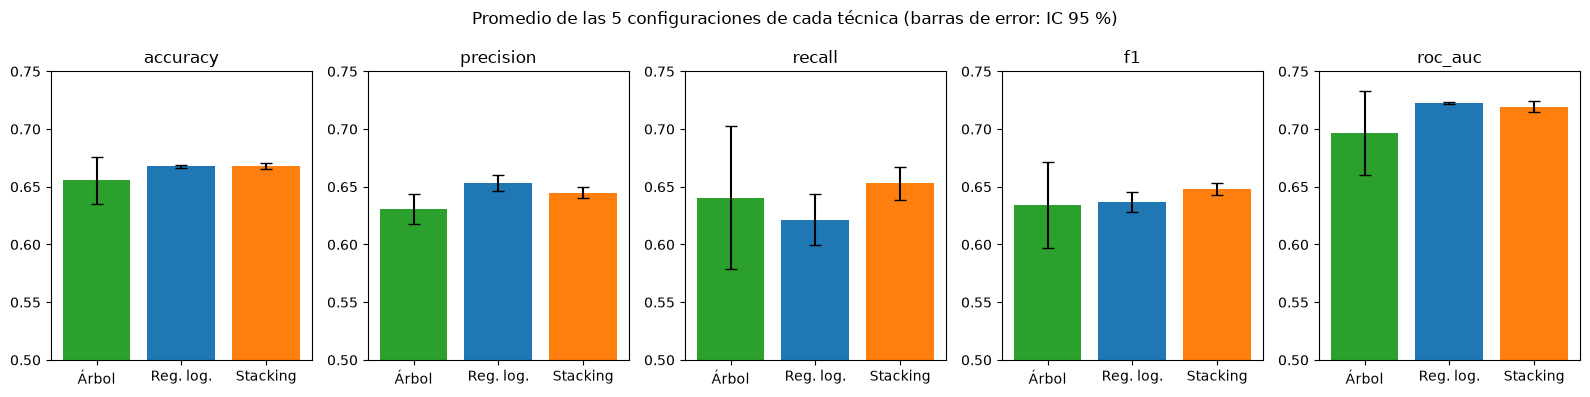

In [8]:
# Promedio de cada técnica con su IC 95 %
fig, axes = plt.subplots(1, len(METRICAS), figsize=(16, 4))
tecnicas = ['Árbol de decisión', 'Regresión logística', 'Stacking']
colores = ['tab:green', 'tab:blue', 'tab:orange']
for ax, m in zip(axes, METRICAS):
    medias = [promedios.loc[m, (t, 'media')] for t in tecnicas]
    errores = [medias[i] - promedios.loc[m, (t, 'IC95 inf')] for i, t in enumerate(tecnicas)]
    ax.bar(range(3), medias, yerr=errores, capsize=4, color=colores)
    ax.set_xticks(range(3), ['Árbol', 'Reg. log.', 'Stacking'])
    ax.set_ylim(0.5, 0.75)
    ax.set_title(m)
fig.suptitle('Promedio de las 5 configuraciones de cada técnica (barras de error: IC 95 %)')
plt.tight_layout()
plt.show()

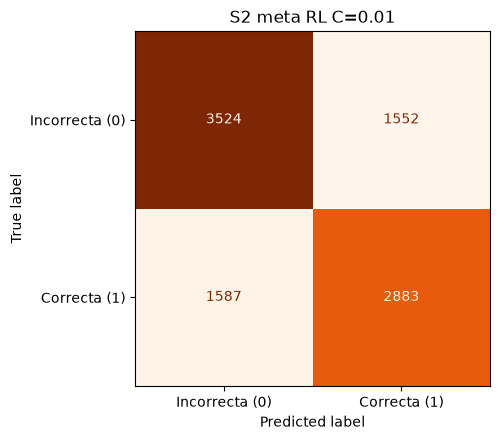

In [9]:
# Matriz de confusión del mejor Stacking (según AUC)
mejor_stack = res_stack['roc_auc'].idxmax()
y_pred = cross_val_predict(crear_pipeline(stackings[mejor_stack]), X, y, cv=cv)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Incorrecta (0)', 'Correcta (1)'],
                                        cmap='Oranges', colorbar=False, ax=ax)
ax.set_title(mejor_stack)
plt.tight_layout()
plt.show()

## 7. ¿Por qué el Stacking no mejora más? Similitud entre los modelos base

Un ensemble solo mejora si sus modelos se equivocan en casos **distintos**. Para medirlo, se calcula la **correlación** entre las probabilidades que predice cada modelo base. Se usan predicciones con CV interno, igual que las que recibe el meta-modelo. Una correlación cercana a 1 significa que dos modelos predicen prácticamente lo mismo.

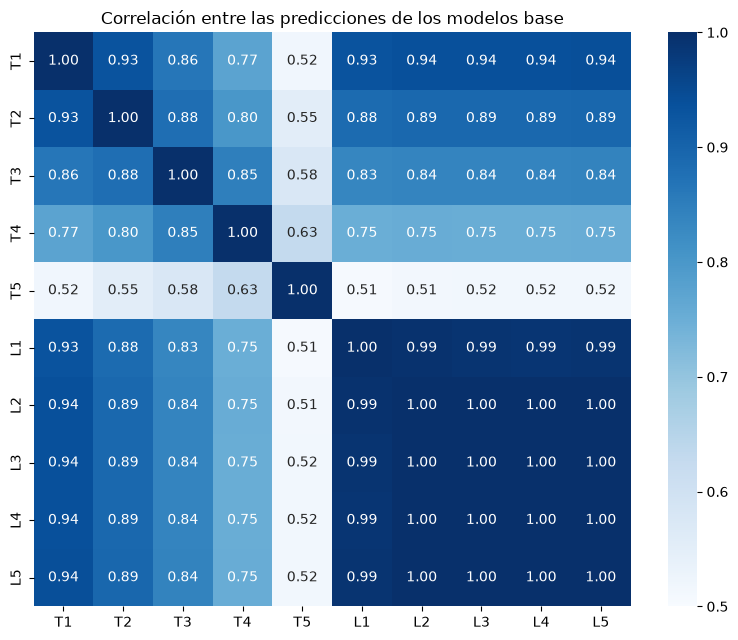

In [10]:
import seaborn as sns

# Probabilidades de cada modelo base, predichas con el CV interno (como las que recibe el meta-modelo)
X_cod = crear_pipeline('passthrough').fit_transform(X, y)  # solo aplica el target encoding
probs = pd.DataFrame({nombre: cross_val_predict(modelo, X_cod, y, cv=cv_interno, method='predict_proba')[:, 1]
                      for nombre, modelo in modelos_base})

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(probs.corr(), annot=True, fmt='.2f', cmap='Blues', vmin=0.5, vmax=1, ax=ax)
ax.set_title('Correlación entre las predicciones de los modelos base')
plt.tight_layout()
plt.show()

### 7.1 ¿A qué modelos base les hace caso el meta-modelo?

Se entrena S2 con todos los datos (solo para interpretar, no para evaluar) y se grafican los coeficientes de su meta-modelo. Se usa S2 porque su regularización fuerte (`C=0,01`) reparte los pesos de forma estable entre modelos muy parecidos. Con poca regularización (S1), los pesos de modelos casi idénticos se vuelven arbitrarios y hasta pueden salir negativos.

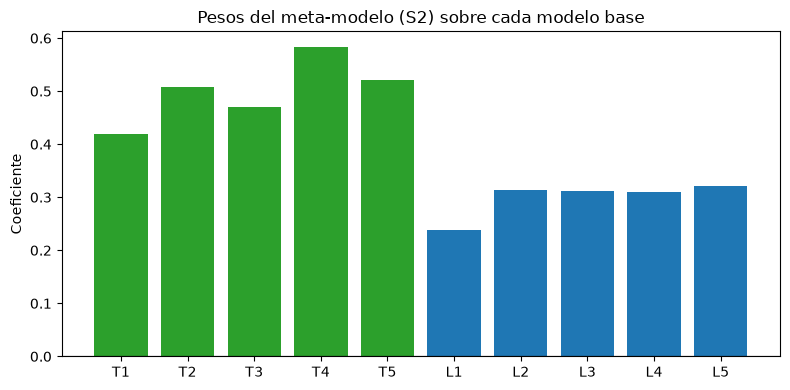

,T1,T2,T3,T4,T5,L1,L2,L3,L4,L5
peso,0.42,0.51,0.47,0.58,0.52,0.24,0.31,0.31,0.31,0.32


In [11]:
s2 = crear_pipeline(stackings['S2 meta RL C=0.01']).fit(X, y)
pesos = pd.Series(s2[-1].final_estimator_.coef_[0], index=[n for n, _ in modelos_base])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pesos.index, pesos.values, color=['tab:green'] * 5 + ['tab:blue'] * 5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Pesos del meta-modelo (S2) sobre cada modelo base')
ax.set_ylabel('Coeficiente')
plt.tight_layout()
plt.show()

display(pesos.round(2).to_frame('peso').T)

In [12]:
# Se guardan los resultados para el informe
res_stack.to_csv(RESULTADOS / 'resultados_tarea3.csv')
promedios.to_csv(RESULTADOS / 'promedios_tarea3.csv')
print('Guardado en', RESULTADOS.relative_to(RAIZ))

Guardado en resultados


## 8. Conclusiones

**1. Resultados de las 5 configuraciones.** Los meta-modelos lineales (S1 a S3) obtienen los mejores resultados: accuracy entre 0,668 y 0,671 y AUC entre 0,722 y 0,723. Los meta-modelos basados en árboles (S4 y S5) quedan apenas por debajo en AUC (0,715 y 0,716), con un accuracy similar (0,665 y 0,667). Darle al meta-modelo acceso a las variables originales (`passthrough`) no aporta mejoras: S3 rinde igual que S1 (accuracy 0,668 frente a 0,669, AUC 0,722 en ambos). Esto indica que las predicciones de los modelos base ya resumen la información útil de los datos. Las diferencias entre configuraciones son menores que la variabilidad entre folds (desvío del accuracy de 1,2 a 1,4 puntos), así que en la práctica las cinco rinden de forma muy similar.

**2. Comparación con la Tarea 2.** Promediando las 5 configuraciones de cada técnica:

| Métrica | Árbol de decisión | Regresión logística | Stacking |
|---|---|---|---|
| Accuracy | 0,655 (IC 95 %: 0,635 – 0,676) | 0,668 (IC 95 %: 0,666 – 0,669) | 0,668 (IC 95 %: 0,665 – 0,671) |
| Precision | 0,630 | 0,653 | 0,645 |
| Recall | 0,641 | 0,622 | 0,653 |
| F1 | 0,634 | 0,637 | 0,648 |
| AUC | 0,697 (IC 95 %: 0,660 – 0,733) | 0,723 (IC 95 %: 0,722 – 0,723) | 0,719 (IC 95 %: 0,715 – 0,724) |

Y comparando la mejor configuración de cada técnica (según AUC):

| | Árbol (T2) | Reg. logística (L5) | Stacking (S2) |
|---|---|---|---|
| Accuracy | 0,666 | 0,669 | 0,671 |
| AUC | 0,717 | 0,723 | 0,723 |
| Errores totales (matriz de confusión) | 3.186 | 3.163 | 3.139 |

El Stacking **empata con la regresión logística**. En promedio obtienen el mismo accuracy (0,668), y sus intervalos de confianza se superponen. Su mejor configuración (S2) supera a la mejor logística por apenas 0,2 puntos de accuracy, con el mismo AUC (24 errores menos sobre 9.546 casos), una diferencia mucho menor que la variabilidad entre folds. Sí supera claramente al árbol de decisión, tanto en rendimiento como en estabilidad.

**3. Lo que sí cambia: un mejor equilibrio entre precision y recall.** El Stacking obtiene el F1 promedio más alto (0,648) y el recall más alto (0,653). En la matriz de confusión, su mejor configuración queda en un punto intermedio entre las dos técnicas: detecta el 64,5 % de las respuestas correctas (frente al 66,6 % del árbol y el 63,1 % de la logística) y el 69,4 % de las incorrectas (frente al 66,7 % y el 70,2 %). Es decir, combina el perfil del árbol, que detecta más respuestas correctas, con el de la logística, que reconoce mejor las incorrectas.

**4. Por qué el Stacking no mejora más: los modelos base son muy parecidos entre sí.** El mapa de correlación (§7) muestra que las 5 regresiones logísticas predicen prácticamente lo mismo (correlación de 0,99 a 1,00): cambiar `C` apenas modifica un modelo lineal. Los árboles T1 a T3 también se parecen mucho a las logísticas (correlación de 0,83 a 0,94). Solo los árboles más profundos se diferencian (T4: 0,75; T5: alrededor de 0,5), pero justamente son los que peor rinden. Un ensemble solo mejora si sus modelos se equivocan en casos distintos. Acá, de los 10 modelos base, varios son casi copias, y los que son distintos lo son porque sobreajustan.

**5. Pesos del meta-modelo.** El meta-modelo de S2 reparte el peso de forma pareja: entre 0,42 y 0,58 para los árboles y entre 0,24 y 0,32 para las logísticas. Como las 5 logísticas son prácticamente idénticas, sus pesos funcionan como uno solo: sumados (1,49) equivalen a darle a "la logística" un peso comparable al del conjunto de árboles. Con poca regularización (S1), en cambio, los pesos de modelos casi idénticos se vuelven arbitrarios y pueden salir negativos (*multicolinealidad*), por lo que no deben interpretarse uno por uno.

**6. Conclusión general.** El Stacking no logra superar el techo de rendimiento de ≈ 67 % que alcanzaron los modelos individuales. Los modelos base usan la misma información y se parecen demasiado entre sí, así que combinarlos no agrega información nueva. En este trabajo, la mejora más importante no vino de combinar modelos, sino de **crear una variable mejor**: `Est_Topic_Level` subió el rendimiento de todos los modelos entre 1,4 y 1,9 puntos (notebook 02, §3.2), más que cualquier diferencia entre técnicas o configuraciones. Es decir, el límite está en la información que contienen los datos y no en el modelo elegido.

En la práctica, el Stacking requiere entrenar los 10 modelos base varias veces en cada fold y es más difícil de interpretar, sin una mejora significativa. Una **regresión logística** logra prácticamente el mismo rendimiento con un modelo mucho más simple, rápido e interpretable, por lo que sería la opción recomendada.